# CRC Atera 教程 01：表达矩阵、官方细胞群与空间分布

**目标**：从一张公开的人结直肠癌 fresh-frozen 切片出发，学习“读取 → 稀疏 QC → 官方 cluster/注释 → 多基因标志检查 → 空间分布”。

**和肾脏案例的关系**：技术主线相同，但细胞群从 CRC 自己的官方元数据中读取，不沿用肾脏 `cluster 16` 或足细胞 marker。

**本教程不做**：细胞过滤、重新聚类、重新注释、恶性细胞判定、H&E 配准、GHIST+ 推理或疾病机制结论。

> 学习方式：从上到下逐格运行。先读 Markdown 的问题，再运行代码，最后尝试回答“读图问题”。已保存的输出只是参考；你应亲自运行并比较。

## 1. 环境与路径

本教程默认使用项目上一级的 `Atera_v1_WTA_S4B_Colorectal_Cancer_FF_outs.zip`。`read_crc_matrix()` 会调用 `prepare_matrix()`：仅当 `input/cell_feature_matrix.zarr.zip` 不存在时，才从外包定点提取这个约 2.96 GB 的成员，再打开**提取后的内层 Zarr ZIP**。本机 Windows 的当前 Zarr 版本不直接读取“外包::内层矩阵”嵌套路径。

原始外包保持不变；不展开约 41 GB 的转录本。已提取的内层 ZIP 会核对大小并运行内部 ZIP 完整性检查。

第一次导入 `anndata`、读取大矩阵可能需要几分钟，请不要反复中断。若文件移动，修改 `scripts/atera_helpers.py` 顶部的 `OUTER_ZIP`。

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 从本教程目录加载辅助函数，不调用肾脏项目的固定 cluster 或 marker。
MODULE_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'scripts' / 'atera_helpers.py').is_file()
                   and p.name == 'crc-atera-learning'), None)
assert MODULE_DIR is not None, '请从 crc-atera-learning 目录运行 notebook'
sys.path.insert(0, str(MODULE_DIR / 'scripts'))
from atera_helpers import read_crc_matrix, sparse_qc, marker_qc, write_software_record

# 图件使用英文，避免不同系统的中文字体造成缺字或编码问题。
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 11, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 120, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False,
})
FIG_DIR = MODULE_DIR / 'output' / 'figures'
TABLE_DIR = MODULE_DIR / 'output' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
print('Python:', sys.executable)
print('Module:', MODULE_DIR)

Python: D:\Deep_learning\CRC_Atera_Learning\.venv\Scripts\python.exe
Module: E:\Atera_v1_example\CRC_Atera\crc-atera-learning


## 2. 读取官方表达对象

`X` 是 **细胞 × feature** 的稀疏计数矩阵；`obs` 是每细胞的坐标、QC、聚类和注释；`var` 是 feature 名称与类型。feature 中既有目标基因，也有技术对照。

这里的 cluster 和 Azimuth 注释是官方输出，**不是本教程重新训练的结果**。

**两种细胞 ID 不要混用**：
- `barcode`：字符串，例如 `aaaacnop-1`；是 AnnData 的行名 `obs_names`，也对应 QC 表导出的 `cell_index`。本教程跨表连接使用它。
- `cell_id`：Atera 的整数细胞 ID，例如 `4294979055`；用于保留平台标识及空间分配结果，**不是** `obs_names`，不能拿来连接 QC 表的 `cell_index`。

本例两者均完整且唯一。标记基因长表也统一使用 `barcode`，避免“字段名叫 cell_id、内容却是 barcode”的隐患。

In [2]:
adata = read_crc_matrix()
print(adata)
print('Matrix type:', type(adata.X))
assert adata.shape == (446777, 24677), '请确认读取的是本教程验证过的 CRC S4B 数据'
print('\nobs fields:', adata.obs.columns.tolist())
print('\nFeature types:')
display(adata.var['feature_type'].value_counts().rename('n_features').to_frame())
display(adata.obs.iloc[:5][['cell_id', 'barcode', 'filtered', 'centroid_column', 'centroid_row',
                            'leiden_res_1.0', 'azimuth_broad', 'azimuth_coarse']])

AnnData object with n_obs × n_vars = 446777 × 24677
    obs: 'barcode', 'cell_id', 'filtered', 'leiden_res_1.0', 'centroid_column', 'centroid_row', 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'is_sketch', 'azimuth_broad', 'azimuth_coarse', 'azimuth_fine', 'azimuth_score', 'azimuth_full_hierarchy'
    var: 'feature_name', 'filtered', 'highly_variable', 'feature_id', 'feature_type', 'genome', 'de_leiden_res_1.0_c15_logfc', 'de_leiden_res_1.0_c15_pval', 'de_leiden_res_1.0_c15_pval_adj', 'de_leiden_res_1.0_c15_score', 'de_leiden_res_1.0_c15_rank', 'de_leiden_res_1.0_c10_logfc', 'de_leiden_res_1.0_c10_pval', 'de_leiden_res_1.0_c10_pval_adj', 'de_leiden_res_1.0_c10_score', 'de_leiden_res_1.0_c10_rank', 'de_leiden_res_1.0_c19_logfc', 'de_leiden_res_1.0_c19_pval', 'de_leiden_res_1.0_c19_pval_adj', 'de_leiden_res_1.0_c19_score', 'de_leiden_res_1.0_c19_rank', 'de_leiden_res_1.0_c17_logfc', 'de_leiden_res_1.0_c17_pval', 'de_

,n_features
feature_type,
Gene Expression,18049
Negative Control Codeword,6390
Unassigned Codeword,91
Negative Control Probe,81
Genomic Control,61
Deprecated Codeword,5


,cell_id,barcode,filtered,centroid_column,centroid_row,leiden_res_1.0,azimuth_broad,azimuth_coarse
barcode,,,,,,,,
aaaacnop-1,4294979055,aaaacnop-1,True,418.732330,3223.197998,3,Epithelial cell,Epithelial cell of intestine
aaaaeneb-1,4294987073,aaaaeneb-1,True,417.548431,3208.330078,16,Epithelial cell,Coarse Not Confidently Annotated
aaaamcia-1,4295017088,aaaamcia-1,True,424.887238,3216.801025,16,Epithelial cell,Epithelial cell of intestine
aaaamojp-1,4295020191,aaaamojp-1,True,432.172424,3157.798096,16,Epithelial cell,Epithelial cell of intestine
aaaaolog-1,4295027686,aaaaolog-1,True,413.197235,3196.215088,3,Epithelial cell,Epithelial cell of intestine


### 坐标与单位

本教程使用官方 `centroid_column/centroid_row` 作为 µm 坐标；它们用于细胞间空间分析。**这不等于已完成 post-run H&E 配准**。后续把细胞投影到 H&E 时，仍需单独核对 `he_imagealignment.csv` 的方向、尺度和偏移。

本次数据范围、组织区域面积和检测指标还会与官方摘要进行一致性核对。

In [3]:
coordinate_summary = adata.obs[['centroid_column', 'centroid_row']].agg(['min', 'max', 'median'])
display(coordinate_summary.round(2))
print('Coordinate ranges are in µm; no H&E transform is applied here.')
official_metrics = pd.read_csv(MODULE_DIR / 'output' / 'inspection' / 'official_metrics_summary.csv')
for field in ['sample_type', 'region_area', 'num_cells_detected', 'median_genes_per_cell', 'median_transcripts_per_cell']:
    print(field, '=', official_metrics.loc[0, field])
assert int(official_metrics.loc[0, 'num_cells_detected']) == adata.n_obs

,centroid_column,centroid_row
min,251.500000,422.250000
max,13014.820312,7468.540039
median,5267.479980,3888.850098


Coordinate ranges are in µm; no H&E transform is applied here.
sample_type = Fresh frozen
region_area = 74.6048863862619
num_cells_detected = 446777
median_genes_per_cell = 2955
median_transcripts_per_cell = 5135


## 3. QC：先描述，不自动删除细胞

按 **10,000 个细胞一块**计算目标基因转录本数和检测基因数，保持矩阵稀疏。保留官方 `filtered` 标记作为诊断信息；本教程不按固定阈值删细胞。

- 低信号可能来自技术质量、分割或真实细胞类型差异。
- 空间原位数据的线粒体比例等阈值不能不加判断地照搬 scRNA-seq。
- 官方 `filtered=True` 的具体判定应查阅该版本文档，不在此猜测为“高质量”或“剔除”。

In [4]:
qc = sparse_qc(adata)
assert len(qc) == adata.n_obs
assert qc[['total_gene_counts', 'detected_genes', 'x', 'y']].notna().all().all()
print('Missing values in official metadata are retained and reported, not silently zero-filled:')
display(adata.obs[['cell_area', 'nucleus_area', 'control_probe_counts', 'control_codeword_counts',
                   'total_counts', 'is_sketch', 'azimuth_score']].isna().sum().rename('n_missing').to_frame())
for column in ['azimuth_broad', 'azimuth_coarse', 'leiden_res_1.0']:
    qc[column] = adata.obs[column].to_numpy()
print('Official filtered flags (descriptive only):')
display(qc['filtered'].value_counts(dropna=False).rename('n_cells').to_frame())
display(qc[['total_gene_counts', 'detected_genes', 'cell_area', 'nucleus_area',
            'control_probe_counts']].describe(percentiles=[.01, .05, .5, .95, .99]).round(2))

Missing values in official metadata are retained and reported, not silently zero-filled:


,n_missing
cell_area,0
nucleus_area,8503
control_probe_counts,0
control_codeword_counts,0
total_counts,0
is_sketch,0
azimuth_score,6


Official filtered flags (descriptive only):


,n_cells
filtered,
True,446234
False,543


,total_gene_counts,detected_genes,cell_area,nucleus_area,control_probe_counts
count,446777.00,446777.00,446777.00,438274.00,446777.00
mean,6314.28,2938.99,69.10,30.53,0.02
std,5447.60,1739.83,43.63,20.67,0.13
min,0.00,0.00,1.44,1.04,0.00
1%,36.00,34.00,10.66,5.10,0.00
5%,151.00,134.00,18.51,7.09,0.00
50%,5135.00,2955.00,59.15,26.14,0.00
95%,16762.20,5832.00,152.66,69.72,0.00
99%,24549.00,6842.00,215.02,99.16,1.00
max,82518.00,9825.00,665.37,412.79,3.00


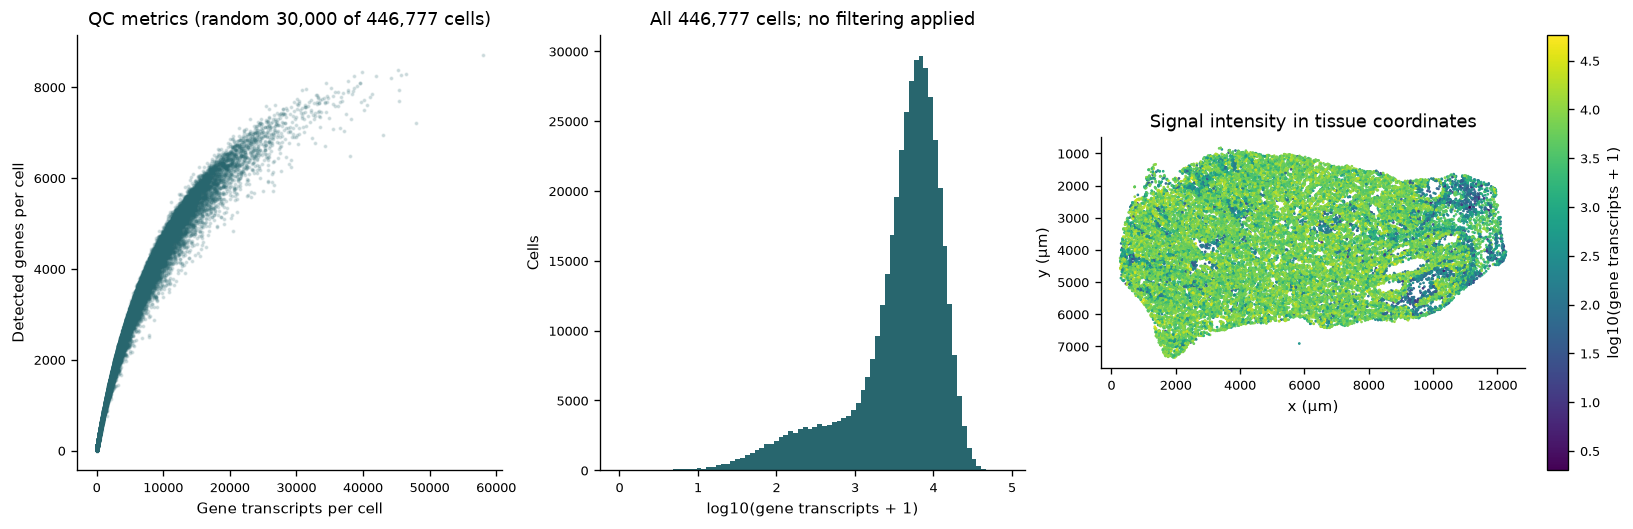

In [5]:
rng = np.random.default_rng(2027)
show = rng.choice(len(qc), size=min(30_000, len(qc)), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), layout='constrained')
sample = qc.iloc[show]
axes[0].scatter(sample.total_gene_counts, sample.detected_genes, s=2, alpha=.15,
                color='#28666e', rasterized=True)
axes[0].set(xlabel='Gene transcripts per cell', ylabel='Detected genes per cell',
            title=f'QC metrics (random {len(sample):,} of {len(qc):,} cells)')
axes[1].hist(np.log10(qc.total_gene_counts + 1), bins=80, color='#28666e')
axes[1].set(xlabel='log10(gene transcripts + 1)', ylabel='Cells',
            title=f'All {len(qc):,} cells; no filtering applied')
sc = axes[2].scatter(sample.x, sample.y, c=np.log10(sample.total_gene_counts + 1),
                     s=.4, cmap='viridis', rasterized=True)
axes[2].set(xlabel='x (µm)', ylabel='y (µm)', title='Signal intensity in tissue coordinates')
axes[2].set_aspect('equal'); axes[2].invert_yaxis()
fig.colorbar(sc, ax=axes[2], label='log10(gene transcripts + 1)')
fig.savefig(FIG_DIR / '01_cell_QC.png', bbox_inches='tight')
plt.show()

# 读图问题：低信号细胞是否空间聚集？这能单独证明低质量吗？

## 4. 官方 cluster 与细胞注释

Leiden 的编号只是**本对象内的类别标签**。肾脏的 `16` 不表示 CRC 的 `16` 也是足细胞或任何指定细胞类型。

本数据同时有：

- `leiden_res_1.0`：表达聚类；
- `azimuth_broad`：粗细胞类型；
- `azimuth_coarse/fine`：更细自动注释；
- `azimuth_score`：自动映射评分，需要结合表达和空间检查。

先用 `azimuth_broad` 做较稳健的粗分类学习；不直接把所有 fine/coarse 标签当作已证实身份。

In [6]:
cluster_counts = adata.obs['leiden_res_1.0'].value_counts(dropna=False).rename('n_cells').to_frame()
cluster_counts['percent'] = 100 * cluster_counts.n_cells / adata.n_obs
print('Official Leiden clusters:')
display(cluster_counts)
broad_counts = adata.obs['azimuth_broad'].value_counts(dropna=False).rename('n_cells').to_frame()
broad_counts['percent'] = 100 * broad_counts.n_cells / adata.n_obs
print('Official broad annotations:')
display(broad_counts.round(2))
cluster_by_broad = pd.crosstab(adata.obs['azimuth_broad'], adata.obs['leiden_res_1.0'])
print('Epithelial annotation spans these clusters:')
display(cluster_by_broad.loc['Epithelial cell'].sort_values(ascending=False).head(10).to_frame('n_cells'))

# “官方细胞群怎么指定？”——用这一列的实际标签筛选，而不是指定通用 cluster 编号。
epithelial_mask = adata.obs['azimuth_broad'].eq('Epithelial cell')
# This is an explicitly chosen teaching example, not a universal CRC cluster.
epithelial_cells = adata.obs.loc[epithelial_mask]
print(f'Epithelial broad annotation: {len(epithelial_cells):,} cells')
assert len(epithelial_cells) > 0

Official Leiden clusters:


,n_cells,percent
leiden_res_1.0,,
3,63820,14.284531
15,29299,6.557858
21,27829,6.228835
10,27295,6.109312
19,25814,5.777827
0,25708,5.754101
17,25095,5.616896
2,21634,4.842237
18,21246,4.755393


Official broad annotations:


,n_cells,percent
azimuth_broad,,
Epithelial cell,259898,58.17
Immune cell,78136,17.49
Fibroblast,64960,14.54
Unassigned,26344,5.90
Endothelial cell,9958,2.23
Perivascular cell,7191,1.61
Glial cell,170,0.04
Neuron,114,0.03
Unannotated,6,0.00


Epithelial annotation spans these clusters:


,n_cells
leiden_res_1.0,
3,62879
15,28977
10,27231
19,25653
17,25041
18,21210
2,20964
5,15222
23,10269


Epithelial broad annotation: 259,898 cells


## 5. UMAP 与组织坐标：回答不同的问题

UMAP 显示表达相似性，邻近不代表组织相邻；空间图保留组织位置，但不直接证明细胞身份。前面的计数与 QC 使用全部细胞。UMAP 为避免过密，每类分层抽至多 2,000 个细胞，**各类显示点数不代表真实比例**；空间图使用全部细胞。稀有/未注释标签仅作官方输出展示，不能当作已确认细胞类型。

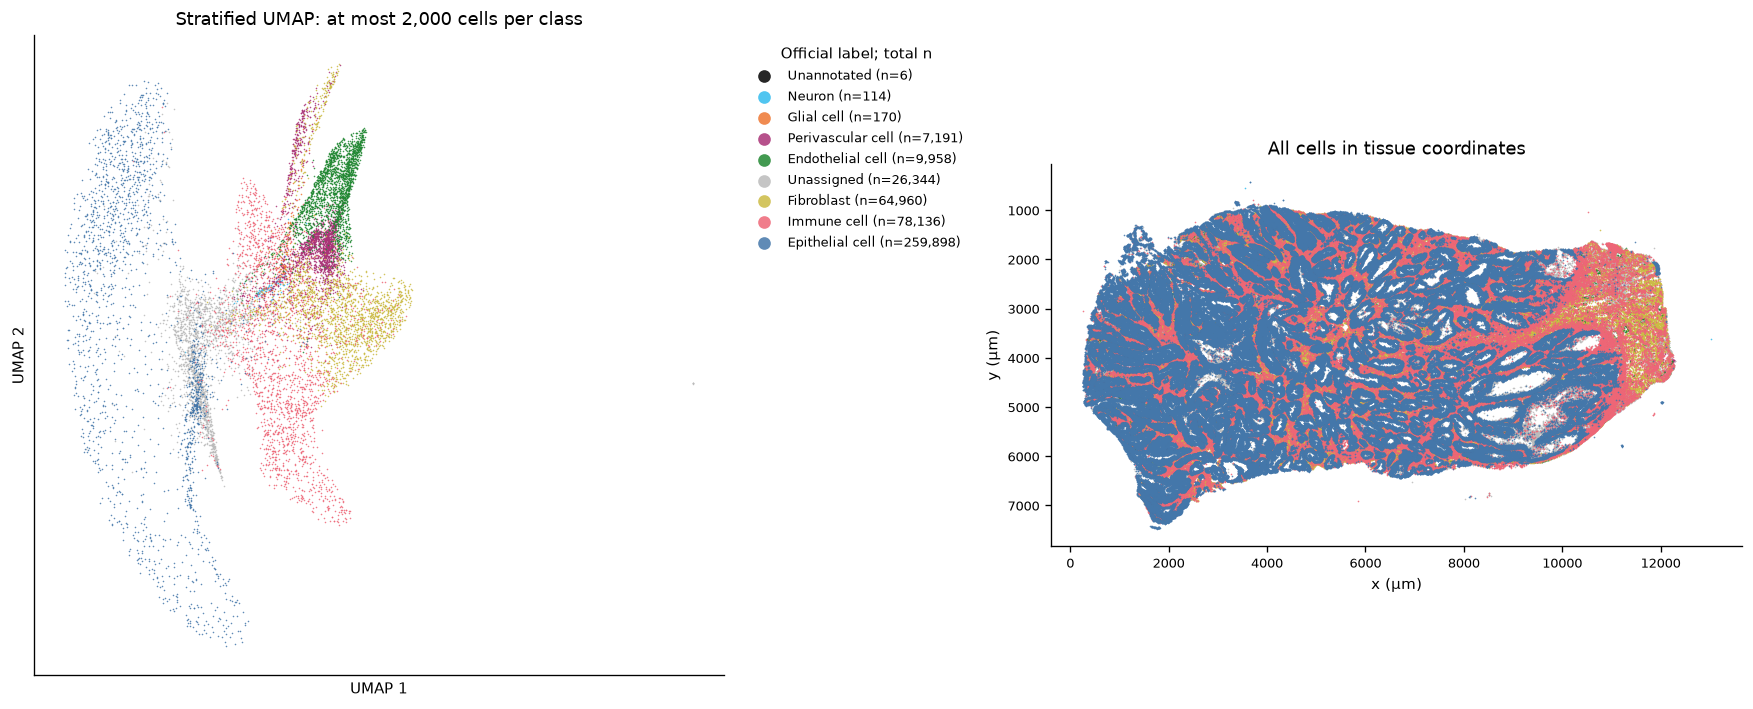

In [7]:
umap_keys = ['X_umap', 'umap', 'X_UMAP']
umap_key = next((key for key in umap_keys if key in adata.obsm), None)
assert umap_key is not None, f'未找到官方 UMAP，实际为 {list(adata.obsm)}'
plot_labels = adata.obs['azimuth_broad'].astype(str)
plot_show = np.sort(np.concatenate([
    rng.choice(np.flatnonzero(plot_labels.eq(label).to_numpy()),
               size=min(2000, int(plot_labels.eq(label).sum())), replace=False)
    for label in plot_labels.unique()
]))
assert set(plot_labels.iloc[plot_show]) == set(plot_labels)
colors = {'Epithelial cell': '#4477aa', 'Immune cell': '#ee6677',
          'Fibroblast': '#ccbb44', 'Endothelial cell': '#228833',
          'Perivascular cell': '#aa3377', 'Unassigned': '#bbbbbb',
          'Glial cell': '#ee7733', 'Neuron': '#33bbee', 'Unannotated': '#000000'}
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), layout='constrained')
for ax, coordinates, title, xlabel in [
        (axes[0], adata.obsm[umap_key], 'Stratified UMAP: at most 2,000 cells per class', 'UMAP 1'),
        (axes[1], adata.obs[['centroid_column', 'centroid_row']].to_numpy(), 'All cells in tissue coordinates', 'x (µm)')]:
    indices = plot_show if ax is axes[0] else np.arange(len(plot_labels))
    label_order = sorted(plot_labels.iloc[indices].unique(), key=lambda x: plot_labels.eq(x).sum())
    for label in label_order:
        selected = plot_labels.iloc[indices].eq(label).to_numpy()
        xy = coordinates[indices[selected]]
        ax.scatter(xy[:, 0], xy[:, 1], s=1.0 if ax is axes[1] else .9,
                   color=colors[label], label=f'{label} (n={plot_labels.eq(label).sum():,})',
                   alpha=.85, linewidths=0, rasterized=True)
    ax.set(xlabel=xlabel, ylabel='UMAP 2' if ax is axes[0] else 'y (µm)', title=title)
    if ax is axes[1]:
        ax.set_aspect('equal'); ax.invert_yaxis()
    else:
        ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(title='Official label; total n', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, markerscale=8)
fig.savefig(FIG_DIR / '02_UMAP_vs_spatial.png', bbox_inches='tight')
plt.show()

# 读图问题：哪些细胞群在 UMAP 中混合？哪些在组织中聚集？

## 6. 多基因标志检查，而不是“看到一个基因就命名”

以下标志用于检查粗注释是否合理：

- 上皮：`EPCAM, KRT8, KRT18, KRT19, CDH1`；
- 成纤维/基质：`COL1A1, COL1A2, DCN`；
- 免疫：`PTPRC`；T 细胞：`CD3D`；髓系：`CD68`；
- 内皮：`PECAM1, VWF`。

这些都是**支持证据而非绝对特异标记**。`EPCAM` 或角蛋白表达不能区分正常与恶性上皮。图中点大小表示阳性细胞比例，颜色表示平均 `log1p(CP10K)`，其中 CP10K = 该基因 count / 该细胞目标基因总 count × 10,000。

In [8]:
markers = ['EPCAM', 'KRT8', 'KRT18', 'KRT19', 'CDH1',
           'COL1A1', 'COL1A2', 'DCN', 'PTPRC', 'CD3D', 'CD68', 'PECAM1', 'VWF']
marker_table = marker_qc(adata, markers)
marker_table['broad'] = marker_table.barcode.map(adata.obs['azimuth_broad'].astype(str))
marker_table['cp10k'] = np.divide(
    marker_table['count'], marker_table.barcode.map(qc.total_gene_counts),
    out=np.zeros(len(marker_table)), where=marker_table.barcode.map(qc.total_gene_counts).to_numpy() > 0,
) * 10_000
assert marker_table['broad'].ne('nan').all(), 'marker barcode 必须连接上官方注释'
marker_summary = marker_table.groupby(['broad', 'gene'], observed=True).agg(
    n_cells=('barcode', 'size'), mean_count=('count', 'mean'),
    fraction_positive=('count', lambda x: (x > 0).mean()),
    mean_log1p_cp10k=('cp10k', lambda x: np.log1p(x).mean())).reset_index()
mean_expression = marker_summary.pivot(index='broad', columns='gene', values='mean_log1p_cp10k').reindex(columns=markers)
fraction_positive = marker_summary.pivot(index='broad', columns='gene', values='fraction_positive').reindex(columns=markers)
assert mean_expression.notna().all().all() and fraction_positive.notna().all().all()
print('Detection fractions by official broad annotation:')
display(fraction_positive.round(3))

Detection fractions by official broad annotation:


gene,EPCAM,KRT8,KRT18,KRT19,CDH1,COL1A1,COL1A2,DCN,PTPRC,CD3D,CD68,PECAM1,VWF
broad,,,,,,,,,,,,,
Endothelial cell,0.190,0.114,0.288,0.046,0.065,0.437,0.524,0.138,0.056,0.048,0.211,0.860,0.878
Epithelial cell,0.981,0.865,0.968,0.728,0.923,0.040,0.094,0.010,0.014,0.010,0.465,0.026,0.010
Fibroblast,0.194,0.154,0.266,0.066,0.081,0.775,0.855,0.461,0.099,0.090,0.315,0.123,0.053
Glial cell,0.059,0.053,0.041,0.018,0.006,0.353,0.412,0.088,0.029,0.035,0.082,0.071,0.006
Immune cell,0.210,0.148,0.258,0.075,0.104,0.377,0.472,0.184,0.440,0.258,0.559,0.345,0.058
Neuron,0.158,0.070,0.088,0.026,0.061,0.158,0.219,0.053,0.009,0.000,0.079,0.096,0.053
Perivascular cell,0.152,0.131,0.302,0.043,0.055,0.542,0.604,0.116,0.045,0.036,0.170,0.284,0.260
Unannotated,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Unassigned,0.137,0.079,0.089,0.025,0.027,0.018,0.024,0.009,0.009,0.008,0.020,0.014,0.011


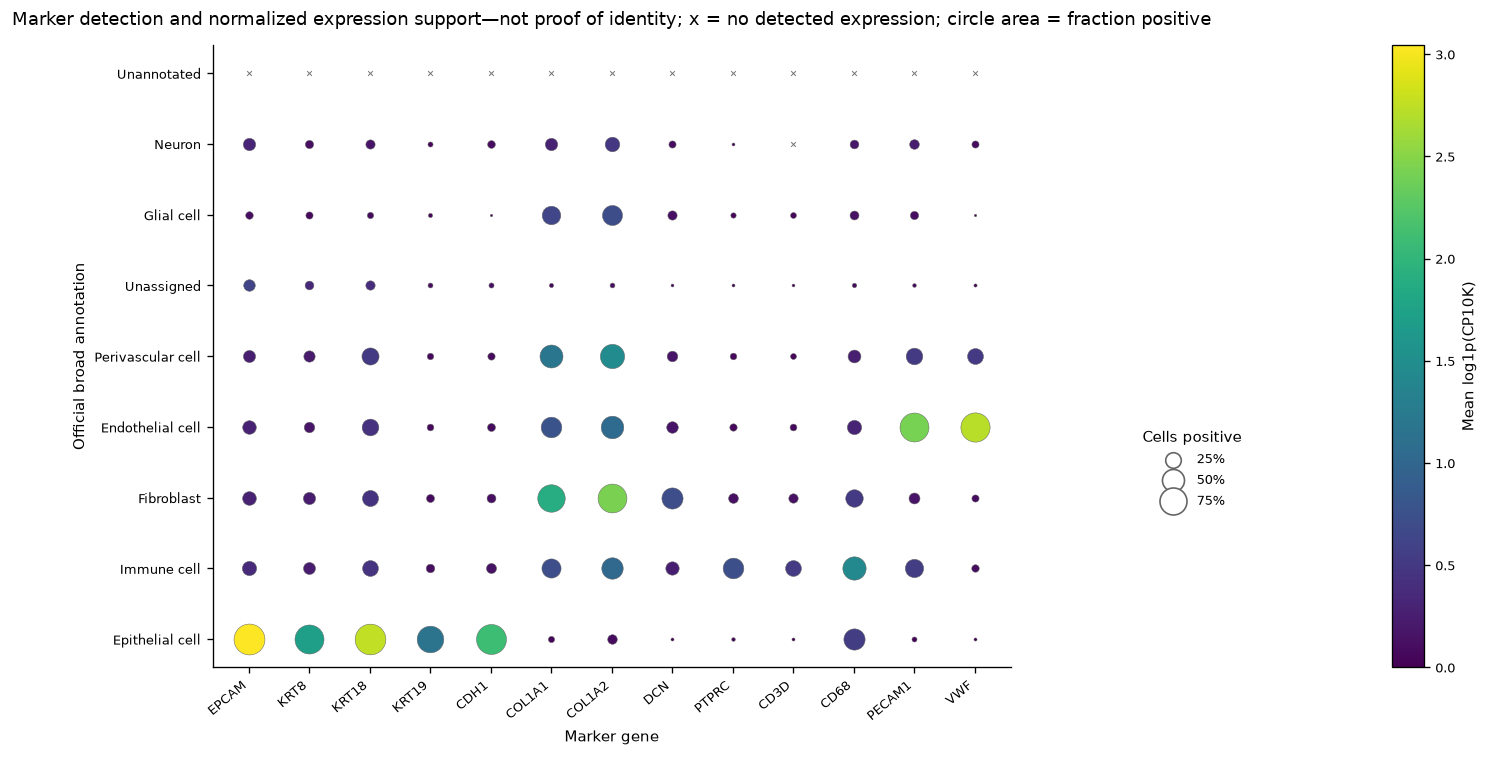

In [9]:
fig, ax = plt.subplots(figsize=(12, 6.2), layout='constrained')
plot_order = [label for label in colors if label in mean_expression.index]
mean_expression = mean_expression.reindex(plot_order)
fraction_positive = fraction_positive.reindex(plot_order)
size_norm = plt.Normalize(0, max(.01, mean_expression.to_numpy().max()))
for x, gene in enumerate(markers):
    for y, label in enumerate(mean_expression.index):
        positive = fraction_positive.loc[label, gene]
        if positive > 0:
            ax.scatter(x, y, s=350 * positive,
                       color=plt.cm.viridis(size_norm(mean_expression.loc[label, gene])),
                       edgecolor='#666666', linewidth=.3)
        else:
            # Zero counts remain visible and auditable instead of disappearing.
            ax.scatter(x, y, s=8, marker='x', color='#777777', linewidth=.6)
ax.set_xticks(range(len(markers)), markers, rotation=40, ha='right')
ax.set_yticks(range(len(mean_expression.index)), mean_expression.index)
ax.set(xlabel='Marker gene', ylabel='Official broad annotation')
ax.set_title('Marker detection and normalized expression support—not proof of identity; '
             'x = no detected expression; circle area = fraction positive', fontsize=11, pad=12)
for size, label in [(0.25, '25%'), (0.5, '50%'), (0.75, '75%')]:
    ax.scatter([], [], s=350 * size, facecolor='white', edgecolor='#666666', label=label)
ax.legend(title='Cells positive', loc='upper left', bbox_to_anchor=(1.15, .4), frameon=False)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=size_norm)
fig.colorbar(sm, ax=ax, label='Mean log1p(CP10K)', pad=.15)
fig.savefig(FIG_DIR / '03_marker_validation.png', bbox_inches='tight')
plt.show()

# 读图问题：非上皮细胞是否也表达部分上皮 marker？为什么不能用 EPCAM 判定恶性？

## 7. 官方 cluster 与注释的交叉核对

cluster 和自动注释不要求一一对应。一个 cluster 可能含多种细胞；同一细胞类型也可分散到多个 cluster。下面导出完整交叉表，供你选择候选群时检查组成，不自动选择“最像肿瘤”的 cluster。

coarse 注释中还可能出现肺、胃等跨组织标签。这不是直接认定样本中存在这些细胞的理由，需要回看 marker、分数、病理形态和参考图谱适用性。

In [10]:
coarse_counts = adata.obs['azimuth_coarse'].value_counts(dropna=False).rename('n_cells').to_frame()
coarse_counts['percent'] = 100 * coarse_counts.n_cells / adata.n_obs
print('Coarse annotation inventory (including uncertain/unassigned labels):')
display(coarse_counts.round(3))
print('Fine annotation score by broad group (descriptive):')
display(adata.obs.groupby('azimuth_broad', observed=True)['azimuth_score'].describe().round(3))

# 只保存轻量结果；不把 446,777 × 24,677 矩阵另存成稠密表。
# QC 表的 cell_index 是 barcode 字符串，不是整数 cell_id。
qc.to_csv(TABLE_DIR / '01_cell_QC.csv', index_label='cell_index')
cluster_counts.to_csv(TABLE_DIR / '01_cluster_counts.csv')
broad_counts.to_csv(TABLE_DIR / '01_broad_annotation_counts.csv')
coarse_counts.to_csv(TABLE_DIR / '01_coarse_annotation_counts.csv')
cluster_by_broad.to_csv(TABLE_DIR / '01_cluster_by_broad_annotation.csv')
marker_summary.to_csv(TABLE_DIR / '01_marker_summary.csv', index=False)
spatial = adata.obs[['cell_id', 'barcode', 'filtered', 'centroid_column', 'centroid_row',
                     'leiden_res_1.0', 'azimuth_broad', 'azimuth_coarse', 'azimuth_score']].copy()
assert adata.obs['barcode'].astype(str).equals(adata.obs_names.astype(str).to_series(index=adata.obs.index))
assert spatial['barcode'].is_unique and spatial['cell_id'].is_unique
spatial['is_epithelial_seed'] = epithelial_mask.to_numpy()
spatial.to_parquet(TABLE_DIR / '01_official_spatial_annotations.parquet')
write_software_record(TABLE_DIR / 'software_versions.json')
print('Saved QC, annotation, marker and lightweight spatial tables; no cells were filtered.')

Coarse annotation inventory (including uncertain/unassigned labels):


,n_cells,percent
azimuth_coarse,,
Epithelial cell of intestine,196527,43.988
Coarse Not Confidently Annotated,97413,21.803
Fibroblast,55670,12.460
Macrophage,30463,6.818
Unassigned,24793,5.549
Endothelial cell,8533,1.910
T cell,7530,1.685
B cell,4286,0.959
Red blood cell,4193,0.938


Fine annotation score by broad group (descriptive):


,count,mean,std,min,25%,50%,75%,max
azimuth_broad,,,,,,,,
Endothelial cell,9958.0,0.726,0.232,0.073,0.543,0.771,0.946,1.000
Epithelial cell,259898.0,0.638,0.267,0.031,0.406,0.646,0.905,1.000
Fibroblast,64960.0,0.711,0.257,0.037,0.492,0.768,0.963,1.000
Glial cell,170.0,0.722,0.214,0.235,0.558,0.761,0.912,0.998
Immune cell,78136.0,0.715,0.270,0.021,0.494,0.784,0.979,1.000
Neuron,114.0,0.695,0.235,0.115,0.497,0.697,0.918,1.000
Perivascular cell,7191.0,0.773,0.205,0.117,0.615,0.828,0.962,1.000
Unannotated,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unassigned,26344.0,0.900,0.153,0.108,0.865,0.980,0.997,1.000


Saved QC, annotation, marker and lightweight spatial tables; no cells were filtered.


## 小结与下一份教程

现在你应该能回答：

1. “官方细胞群”来自哪张表、哪个字段？如何用标签筛选？
2. 为什么不能把肾脏 cluster 16 用到 CRC？
3. 为什么需要 cluster、自动注释、多个 marker 和空间位置共同核对？
4. 为什么本次只做 QC 描述而不自动过滤？

下一份教程将 `azimuth_broad == 'Epithelial cell'` 作为**官方上皮注释种子**，构建候选上皮注释区域和距离带。它不代表恶性细胞，也不是病理医师勾画的肿瘤或侵袭前沿。